# offaxsim: worked examples

This notebook introduces the Python API for a single uniaxial layer and a multilayer stack with antireflection coatings (ARCs). It explains the geometry, array layout, and polarization conventions, then checks a few basic consistency limits.

Run the cells from top to bottom. All numerical inputs below are illustrative and follow the project's existing example parameters; they are not a general material calibration. Both exterior media are air. The simulation API returns **transmission**, not reflection or absorption.

## 1. Environment setup

In a terminal, change into the directory containing `pyproject.toml`, then run:

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install -e ".[plot]" jupyterlab ipykernel
python -m ipykernel install --user --name offaxsim --display-name "Python (offaxsim)"
python -m jupyterlab src/notebooks/example_usage.ipynb
```

On Windows PowerShell, replace the activation command with `.\.venv\Scripts\Activate.ps1`.
Choose the **Python (offaxsim)** kernel in JupyterLab. The package declares Python >= 3.9; this notebook was executed with Python 3.10.9. Installation commands are shown as instructions rather than executable notebook cells.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import offaxsim
from offaxsim import (
    SingleLayerSimulation, MultiLayerSimulation,
    build_single_layer, build_hwp_stack,
    build_klopfenstein_arc, wrap_with_symmetric_arc,
    jones_to_mueller,
)

print("Python:", sys.version.split()[0])
print("offaxsim:", offaxsim.__version__)
np.set_printoptions(precision=5, suppress=True)

Python: 3.10.9
offaxsim: 0.1.0


## 2. Geometry and units

The surface normal is the z axis and the incidence plane is yz. The incident direction is
$\hat{k}=(0,\sin\theta,\cos\theta)$, where `theta_deg` is the external incidence angle.
The optical axis is

$$\boldsymbol{\xi}=(-\cos\psi\sin\rho,\;\cos\psi\cos\rho,\;\sin\psi).$$

Here `psi_deg` is tilt out of the xy plane and `rho_arr` is rotation about z. For example, `psi=0, rho=0` gives +y, and `psi=0, rho=90°` gives -x. Keep the solver option `t_axis="y"` for this geometry.

| Quantity | Unit / interpretation |
| --- | --- |
| Frequency | Hz; multiply GHz by `1e9` |
| Thickness | m; multiply mm by `1e-3` |
| Public angle inputs | Degrees |
| `no`, `ne` | Ordinary and principal extraordinary refractive indices |

The indices are constant across each frequency sweep. Complex values are accepted; the existing examples use negative imaginary parts for loss. Even a single frequency or rotation must be supplied as a one-dimensional array.

In [2]:
freq = np.linspace(60.0, 120.0, 61) * 1e9
rho_arr = np.linspace(0.0, 180.0, 37)
theta_deg = 10.0
no = 3.059 - 0.000137655j
ne = 3.397 - 0.00023779j
thickness_m = 5e-3
psi_deg = 30.0

print("Frequencies:", freq.size, "  Rotations:", rho_arr.size)

Frequencies: 61   Rotations: 37


## 3. Single-layer transmission

`run` returns `(J, M)`. The first two axes are rotation and frequency, in that order. The remaining axes are the Jones (2 × 2) or Mueller (4 × 4) matrix dimensions. Set `return_mueller=False` to obtain `(J, None)` when Mueller matrices are unnecessary.

The assertions check shapes and finite values. They do not establish physical accuracy.

In [3]:
single = SingleLayerSimulation(theta_deg)
J_single, M_single = single.run(
    freq=freq, rho_arr=rho_arr,
    no=no, ne=ne, thickness_m=thickness_m, psi_deg=psi_deg,
    show_progress=False,
)
assert J_single.shape == (rho_arr.size, freq.size, 2, 2)
assert M_single.shape == (rho_arr.size, freq.size, 4, 4)
assert np.isfinite(J_single).all() and np.isfinite(M_single).all()
print("Jones shape:", J_single.shape)
print("Mueller shape:", M_single.shape)

rho_index = int(np.argmin(np.abs(rho_arr - 45.0)))
freq_index = int(np.argmin(np.abs(freq - 90e9)))
print("Selected rotation [deg]:", rho_arr[rho_index])
print("Selected frequency [GHz]:", freq[freq_index] / 1e9)
print("Jones matrix:\n", J_single[rho_index, freq_index])
print("Mueller matrix:\n", M_single[rho_index, freq_index])

Jones shape: (37, 61, 2, 2)
Mueller shape: (37, 61, 4, 4)
Selected rotation [deg]: 45.0
Selected frequency [GHz]: 90.0
Jones matrix:
 [[0.17388+0.46548j 0.69967-0.10266j]
 [0.70365-0.10365j 0.06586+0.48j   ]]
Mueller matrix:
 [[ 0.7438   0.00897  0.07046 -0.00104]
 [ 0.00319 -0.26215  0.07728  0.68812]
 [ 0.0709   0.0773   0.73785 -0.05309]
 [-0.00295 -0.68817  0.05253 -0.26808]]


### Read the Jones elements

The returned matrix is arranged as
$J=\begin{pmatrix}t_{pp}&t_{ps}\\t_{sp}&t_{ss}\end{pmatrix}$ in the `(p, s)` basis: rows label output components and columns label input components.
The forward air basis is $p=(0,\cos\theta,-\sin\theta)$ and $s=(1,0,0)$.

For unit p-polarized input, the two output channel powers are $|t_{pp}|^2$ and $|t_{sp}|^2$. With the current air-to-air boundaries, their sum is the total transmission for that input. Using only $|t_{pp}|^2$ omits cross-polarized transmission. The same column-sum rule applies to s-polarized input.

The following plot shows frequency dependence at the selected rotation. No normalization to peak transmission is applied.

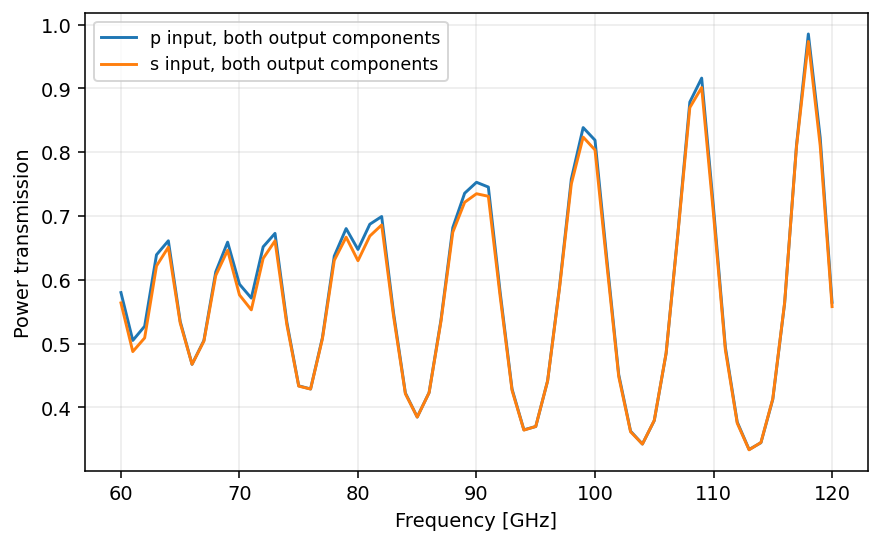

In [4]:
T_p = np.sum(np.abs(J_single[..., :, 0])**2, axis=-1)
T_s = np.sum(np.abs(J_single[..., :, 1])**2, axis=-1)

fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(freq / 1e9, T_p[rho_index], label="p input, both output components")
ax.plot(freq / 1e9, T_s[rho_index], label="s input, both output components")
ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Power transmission")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 4. Mueller matrices and the sign of V

Stokes vectors are ordered `(I, Q, U, V)`. With $C_{ab}=E_aE_b^*$ in the `(p, s)` basis, this implementation uses

$$I=C_{pp}+C_{ss},\quad Q=C_{pp}-C_{ss},\quad
U=C_{ps}+C_{sp},\quad V=i(C_{ps}-C_{sp}).$$

Thus $E=(1,i)/\sqrt{2}$ has $V=+1$. Check the sign convention before comparing circular polarization with other software.

For each frequency and rotation, `S_out = M @ S_in`. The next cell compares the Mueller result with the Stokes vector calculated directly from the transmitted Jones vector. This checks conversion consistency, not the underlying propagation model.

In [5]:
def stokes_from_jones_vector(E):
    Ep, Es = E
    Cps = Ep * np.conjugate(Es)
    return np.array([
        np.abs(Ep)**2 + np.abs(Es)**2,
        np.abs(Ep)**2 - np.abs(Es)**2,
        2.0 * np.real(Cps),
        -2.0 * np.imag(Cps),
    ])

E_in = np.array([1.0, 1.0j]) / np.sqrt(2.0)
S_in = stokes_from_jones_vector(E_in)
np.testing.assert_allclose(S_in, [1.0, 0.0, 0.0, 1.0], atol=1e-12)
E_out = J_single[rho_index, freq_index] @ E_in
S_from_J = stokes_from_jones_vector(E_out)
S_from_M = M_single[rho_index, freq_index] @ S_in
np.testing.assert_allclose(S_from_J, S_from_M, rtol=1e-10, atol=1e-12)
print("Input Stokes:", S_in)
print("Output Stokes from Jones:", S_from_J)
print("Output Stokes from Mueller:", S_from_M)

Input Stokes: [1. 0. 0. 1.]
Output Stokes from Jones: [ 0.74276  0.69131  0.01782 -0.27103]
Output Stokes from Mueller: [ 0.74276  0.69131  0.01782 -0.27103]


## 5. Multilayer stack with symmetric ARCs

`build_hwp_stack` creates layers with shared `no`, `ne`, and tilt, and individual thicknesses and rotation offsets. It does not optimize a half-wave plate. The effective rotation of each layer is `rho_arr[i] + opt_axis_arr_deg[layer]`.

`build_klopfenstein_arc` discretizes a coating into `num - 1` isotropic layers. `h_m` is the total thickness of one coating. `ns` and `n0` define the profile endpoints; they do not change the simulation's air boundaries. For this increasing real-index profile, choose `ns > n0 > 0`, `h_m > 0`, `num >= 2`, and `0 < Gamma_m < 0.5 * log(ns / n0)`.

`wrap_with_symmetric_arc` combines `arc + core + arc.reversed()`. Reversal reverses array order without changing angle signs. The example contains 25 layers. Its core tilt (10°) differs from the single-layer example (30°); the comparison below uses the same core with and without coatings.

In [6]:
core = build_hwp_stack(
    no=no, ne=ne,
    thickness_arr_m=np.full(5, 5e-3),
    psi_deg=10.0,
    opt_axis_arr_deg=[88.65, 61.68, 0.0, 61.68, 88.65],
)
arc = build_klopfenstein_arc(
    h_m=2e-3, num=11, ns=3.397, n0=1.0,
    Gamma_m=0.03878242227997966,
)
stack = wrap_with_symmetric_arc(core, arc)
assert stack.Nlayer == 25

multi = MultiLayerSimulation(theta_deg)
J_core, M_core = multi.run(freq, rho_arr, core, show_progress=False)
J_arc, M_arc = multi.run(freq, rho_arr, stack, show_progress=False)
for array in (J_core, M_core, J_arc, M_arc):
    assert np.isfinite(array).all()
print("Core layers:", core.Nlayer, "  Coated stack layers:", stack.Nlayer)
print("Coated Jones shape:", J_arc.shape)

Core layers: 5   Coated stack layers: 25
Coated Jones shape: (37, 61, 2, 2)


### Compare unpolarized transmission

For unit unpolarized input, `S_in = [1, 0, 0, 0]`, so the transmitted intensity is `M[..., 0, 0]`. It also equals half the sum of the four squared Jones magnitudes. The comparison does not imply that the coating improves every frequency, angle, or polarization.

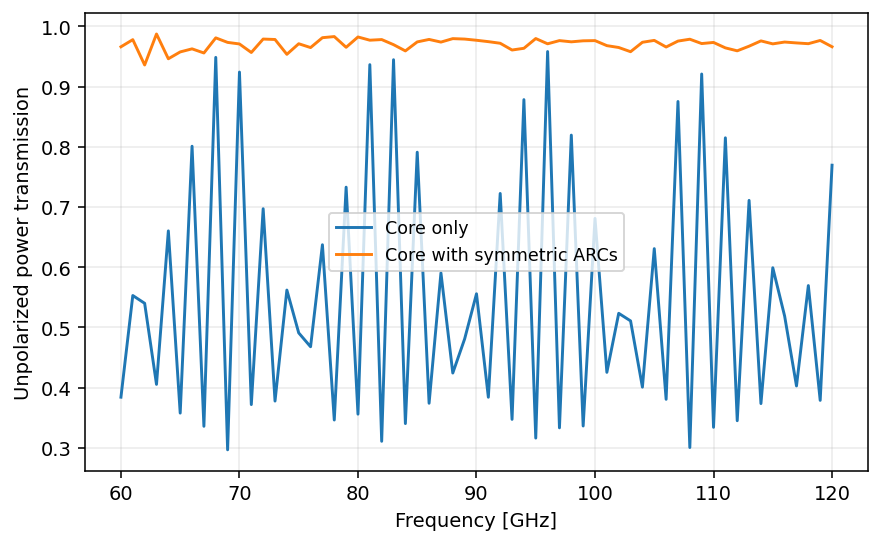

In [7]:
np.testing.assert_allclose(
    M_arc[..., 0, 0],
    0.5 * np.sum(np.abs(J_arc)**2, axis=(-2, -1)),
    rtol=1e-10, atol=1e-12,
)
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(freq / 1e9, M_core[rho_index, :, 0, 0], label="Core only")
ax.plot(freq / 1e9, M_arc[rho_index, :, 0, 0], label="Core with symmetric ARCs")
ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Unpolarized power transmission")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Basic consistency checks

Compare the single-layer and multilayer paths for identical inputs, check that zero thickness gives the identity Jones matrix, and check the identity Jones-to-Mueller conversion. A small sweep keeps this cell quick. Agreement between paths that share code is not an independent physical validation.

In [8]:
f_check = np.array([60.0, 90.0, 120.0]) * 1e9
r_check = np.array([0.0, 45.0, 90.0])
params = dict(no=no, ne=ne, thickness_m=thickness_m, psi_deg=psi_deg)
J1, M1 = single.run(f_check, r_check, **params, show_progress=False)
J2, M2 = multi.run(
    f_check, r_check, build_single_layer(**params), show_progress=False,
)
np.testing.assert_allclose(J1, J2, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(M1, M2, rtol=1e-10, atol=1e-12)

J0, no_mueller = single.run(
    f_check, r_check, **dict(params, thickness_m=0.0),
    return_mueller=False, show_progress=False,
)
assert no_mueller is None
np.testing.assert_allclose(
    J0, np.broadcast_to(np.eye(2), J0.shape), rtol=1e-10, atol=1e-12,
)
np.testing.assert_allclose(jones_to_mueller(np.eye(2)), np.eye(4), atol=1e-12)
print("All basic consistency checks passed.")

All basic consistency checks passed.


## 7. Optional: save results

Set `SAVE_RESULTS = True` to save the single-layer and coated-stack results together with their coordinates and material/geometry parameters. The output directory is relative to the notebook kernel's working directory. Existing files with the same names will be overwritten. Saving is disabled by default.

In [9]:
from pathlib import Path

SAVE_RESULTS = False
if SAVE_RESULTS:
    output_dir = Path("example_results")
    output_dir.mkdir(exist_ok=True)
    np.savez_compressed(
        output_dir / "single_layer.npz",
        freq_Hz=freq, rho_deg=rho_arr, J=J_single, M=M_single,
        theta_deg=theta_deg, no=no, ne=ne,
        thickness_m=thickness_m, psi_deg=psi_deg,
    )
    np.savez_compressed(
        output_dir / "coated_stack.npz",
        freq_Hz=freq, rho_deg=rho_arr, J=J_arc, M=M_arc,
        theta_deg=theta_deg,
        no_arr=stack.no_arr, ne_arr=stack.ne_arr, d_arr_m=stack.d_arr,
        psi_arr_deg=stack.psi_arr, opt_axis_arr_deg=stack.opt_axis_arr,
    )
    print("Saved results to:", output_dir.resolve())
else:
    print("Saving is disabled. Set SAVE_RESULTS = True to export arrays.")

Saving is disabled. Set SAVE_RESULTS = True to export arrays.


## Limitations and next steps

- Exterior media are fixed to air; the API does not expose general substrate/incident boundary indices.
- Each layer has frequency-independent indices during a run. For dispersion, run individual frequencies with the corresponding indices.
- Optical-axis alignment with propagation can make the mode basis singular. Grazing incidence and thick or strongly attenuating stacks can be numerically problematic.
- Layer products are implemented as `T_last @ ... @ T_first`. Check the physical orientation of an asymmetric stack against an independent reference.
- These examples verify execution and internal consistency. They do not validate all tilted-axis, cross-polarized, lossy, or evanescent cases.

See [the README](../../README.md) for the API conventions and [the existing comparison notebook](consistency_check.ipynb) for stored-reference comparisons. The comparison notebook has an uninstall cell at the end; skip it if keeping the package installed.